# BTC and ETH price exploration

Original file name: `Cryptocurrency Analysis & Visualisation.ipynb`

**Runs from the data committed in this repository** (`data/derived/`, `data/prices/`, `data/tweet_counts/`, `data/annotation/`). Environment: see `requirements.txt` (Python 3.11, pandas 1.5.3). The Plotly candlestick charts near the end are interactive and do not render on GitHub; run the notebook locally to see them.

In [1]:
# packages
!pip install -q plotly

In [2]:
# libraries 
from pandas_datareader import data as pdr
from pandas. plotting import scatter_matrix
from pandas.plotting import lag_plot
from pandas.plotting import autocorrelation_plot
import matplotlib.pyplot as plt
import pandas as pd
import datetime as dt
import numpy as np
import plotly.graph_objects as go

In [3]:
#read files 
btc_data = pd.read_csv("../data/prices/BTC-USD_1d_2021.csv")
eth_data = pd.read_csv("../data/prices/ETH-USD_1d_2021.csv")

In [4]:
btc_data

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits,Returns
0,2021-01-01,28994.009766,29600.626953,28803.585938,29374.152344,40730301359,0,0,NaN
1,2021-01-02,29376.455078,33155.117188,29091.181641,32127.267578,67865420765,0,0,0.093726
2,2021-01-03,32129.408203,34608.558594,32052.316406,32782.023438,78665235202,0,0,0.020380
3,2021-01-04,32810.949219,33440.218750,28722.755859,31971.914062,81163475344,0,0,-0.024712
4,2021-01-05,31977.041016,34437.589844,30221.187500,33992.429688,67547324782,0,0,0.063197
...,...,...,...,...,...,...,...,...,...
360,2021-12-27,50802.609375,51956.328125,50499.468750,50640.417969,24324345758,0,0,-0.003328
361,2021-12-28,50679.859375,50679.859375,47414.210938,47588.855469,33430376883,0,0,-0.060259
362,2021-12-29,47623.871094,48119.742188,46201.496094,46444.710938,30049226299,0,0,-0.024042
363,2021-12-30,46490.605469,47879.964844,46060.312500,47178.125000,26686491018,0,0,0.015791


In [5]:
eth_data

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits,Returns
0,2021-01-01,737.708374,749.201843,719.792236,730.367554,13652004358,0,0,NaN
1,2021-01-02,730.402649,786.798462,718.109497,774.534973,19740771179,0,0,0.060473
2,2021-01-03,774.511841,1006.565002,771.561646,975.507690,45200463368,0,0,0.259475
3,2021-01-04,977.058838,1153.189209,912.305359,1040.233032,56945985763,0,0,0.066350
4,2021-01-05,1041.498779,1129.371460,986.811279,1100.006104,41535932781,0,0,0.057461
...,...,...,...,...,...,...,...,...,...
360,2021-12-27,4064.746338,4126.001465,4033.492432,4037.547607,11424360002,0,0,-0.007322
361,2021-12-28,4037.538086,4037.538086,3769.280029,3800.893066,17299472803,0,0,-0.058613
362,2021-12-29,3797.436279,3827.981934,3612.795898,3628.531738,15722555672,0,0,-0.045348
363,2021-12-30,3632.219727,3767.559814,3595.204834,3713.852051,12925377999,0,0,0.023514


# Crypto Time Series plot

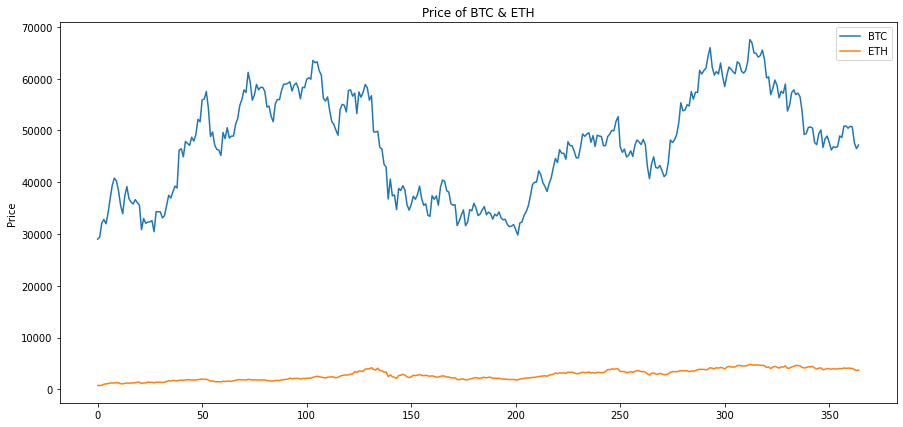

In [6]:
btc_data['Open'].plot(label='BTC', figsize=(15, 7))
eth_data['Open'].plot(label='ETH')
plt.ylabel('Price')
plt.title('Price of BTC & ETH')
plt.legend()

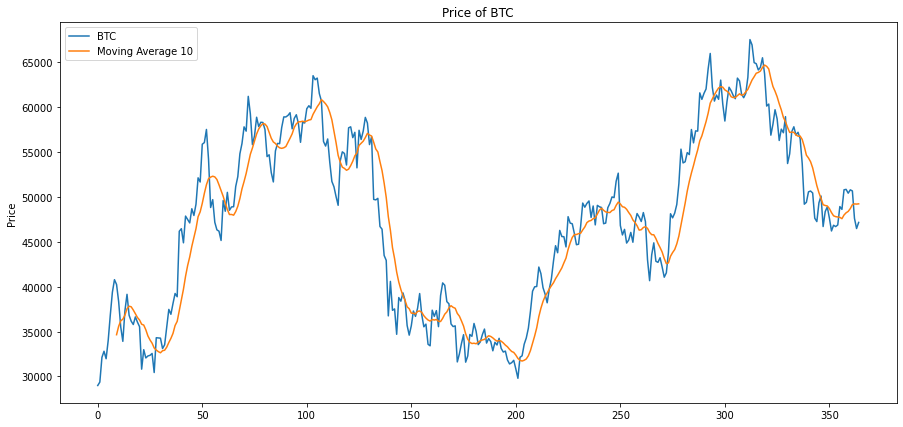

In [7]:
btc_data['Open'].plot(label='BTC', figsize=(15, 7))
btc_data['MA10'] = btc_data['Open'].rolling(10).mean()
btc_data['MA10'].plot(label='Moving Average 10')
plt.ylabel('Price')
plt.title('Price of BTC')
plt.legend()

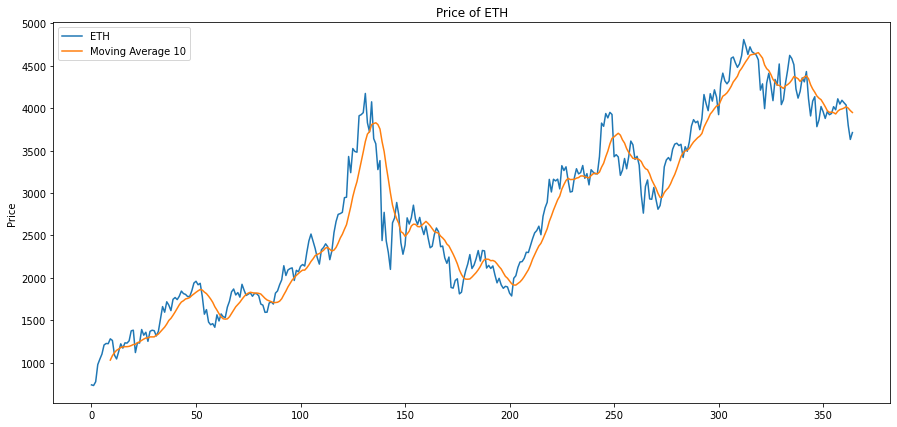

In [8]:
eth_data['Open'].plot(label='ETH', figsize=(15, 7))
eth_data['MA10'] = eth_data['Open'].rolling(10).mean()
eth_data['MA10'].plot(label='Moving Average 10')
plt.ylabel('Price')
plt.title('Price of ETH')
plt.legend()

# Volume Traded Time Series Plot

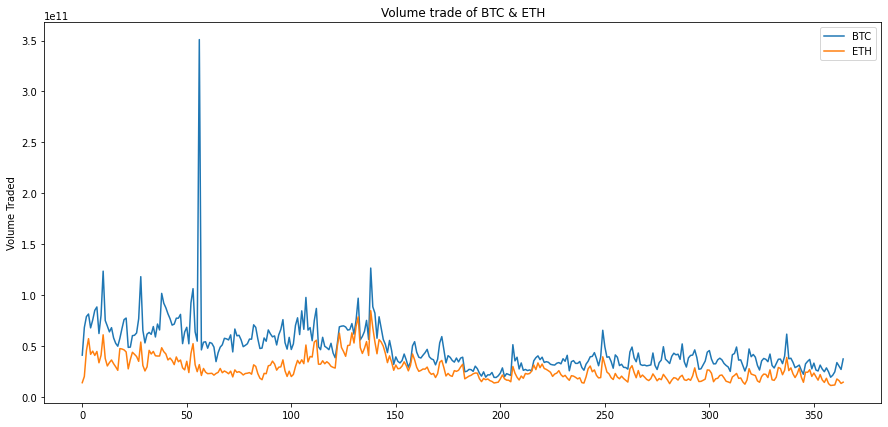

In [9]:
btc_data['Volume'].plot(label='BTC', figsize=(15, 7))
eth_data['Volume'].plot(label='ETH')
plt.ylabel('Volume Traded')
plt.title('Volume trade of BTC & ETH')
plt.legend()

# Total Transaction Time Series Plot

In [10]:
btc_data['Total Traded'] = btc_data['Open'] * btc_data['Volume'] 
eth_data['Total Traded'] = eth_data['Open'] * eth_data['Volume']

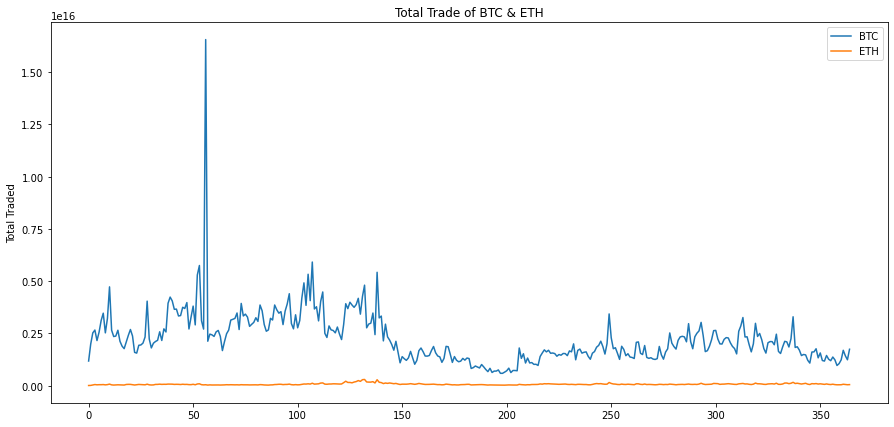

In [11]:
btc_data['Total Traded'].plot(label='BTC', figsize=(15, 7))
eth_data['Total Traded'].plot(label='ETH')
plt.ylabel('Total Traded')
plt.title('Total Trade of BTC & ETH')
plt.legend()

# Time Series Analysis

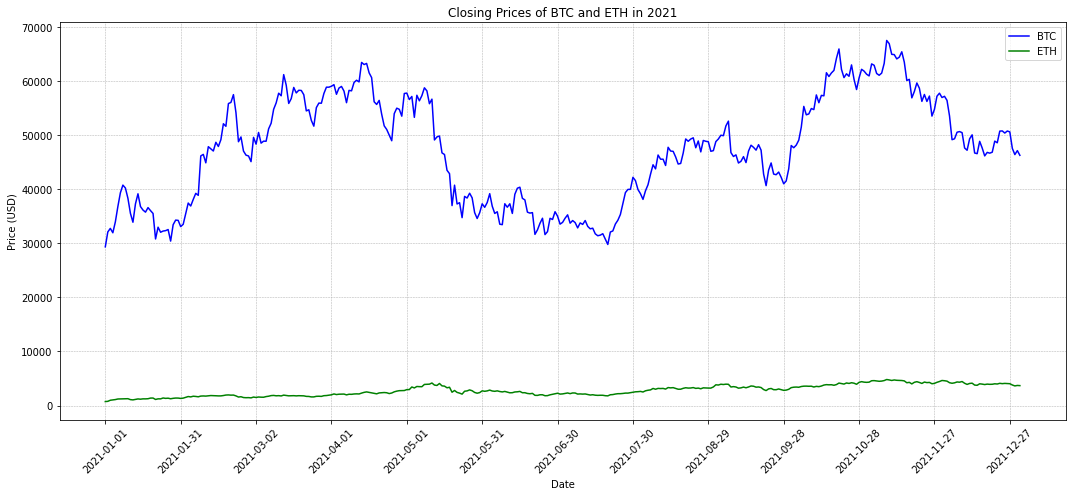

In [12]:
plt.figure(figsize=(15, 7))

# Bitcoin
plt.plot(btc_data['Date'], btc_data['Close'], label='BTC', color='blue')

# Ethereum
plt.plot(eth_data['Date'], eth_data['Close'], label='ETH', color='green')

# Formatting the plot
plt.title('Closing Prices of BTC and ETH in 2021')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.xticks(btc_data['Date'][::30], rotation=45)  # Display every 30th date for clarity
plt.legend()
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.tight_layout()

plt.show()

# Scatter Matrix of BTC & ETH open prices

array([[<Axes: xlabel='BTC Open', ylabel='BTC Open'>,
        <Axes: xlabel='ETH Open', ylabel='BTC Open'>],
       [<Axes: xlabel='BTC Open', ylabel='ETH Open'>,
        <Axes: xlabel='ETH Open', ylabel='ETH Open'>]], dtype=object)

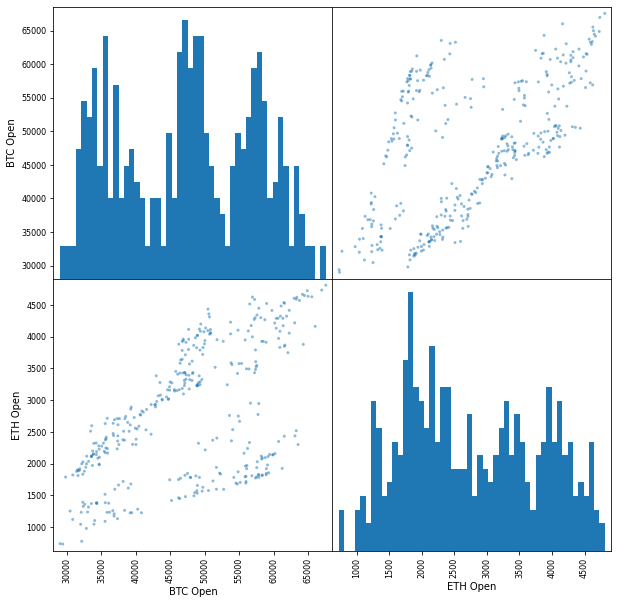

In [13]:
crypto = pd.concat([btc_data['Open'], eth_data['Open']], axis = 1)
crypto.columns = ['BTC Open', 'ETH Open']
scatter_matrix(crypto, figsize=(10, 10), hist_kwds={'bins':50})

# Scatter Matrix of BTC & ETH Volume

array([[<Axes: xlabel='BTC Volume', ylabel='BTC Volume'>,
        <Axes: xlabel='ETH Volume', ylabel='BTC Volume'>],
       [<Axes: xlabel='BTC Volume', ylabel='ETH Volume'>,
        <Axes: xlabel='ETH Volume', ylabel='ETH Volume'>]], dtype=object)

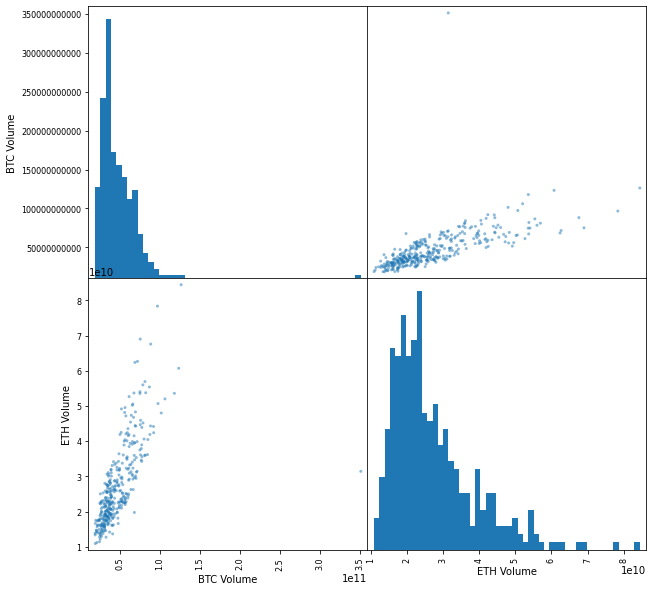

In [14]:
crypto = pd.concat([btc_data['Volume'], eth_data['Volume']], axis = 1)
crypto.columns = ['BTC Volume', 'ETH Volume']
scatter_matrix(crypto, figsize=(10, 10), hist_kwds={'bins':50})

# Scatter Matrix of BTC & ETH Returns

array([[<Axes: xlabel='BTC Returns', ylabel='BTC Returns'>,
        <Axes: xlabel='ETH Returns', ylabel='BTC Returns'>],
       [<Axes: xlabel='BTC Returns', ylabel='ETH Returns'>,
        <Axes: xlabel='ETH Returns', ylabel='ETH Returns'>]], dtype=object)

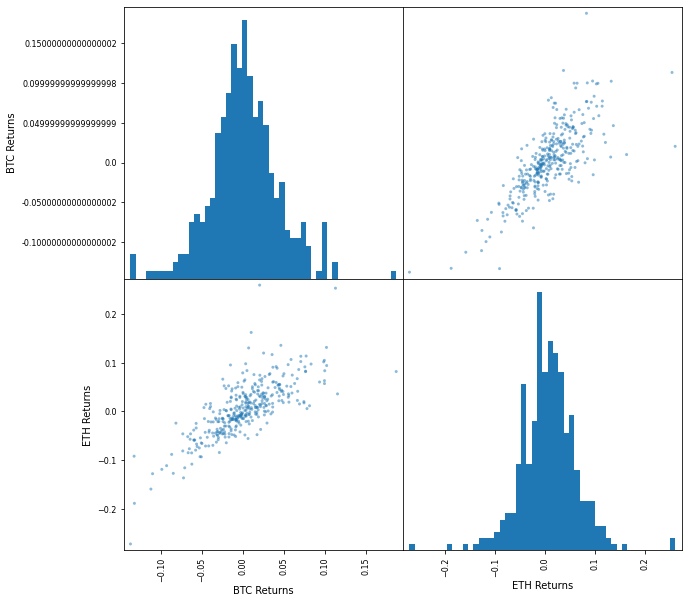

In [15]:
crypto = pd.concat([btc_data['Returns'], eth_data['Returns']], axis = 1)
crypto.columns = ['BTC Returns', 'ETH Returns']
scatter_matrix(crypto, figsize=(10, 10), hist_kwds={'bins':50})

<Axes: >

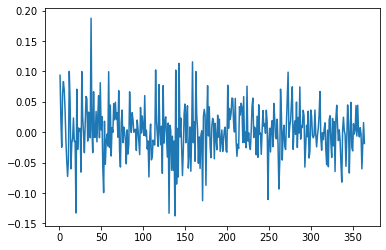

In [16]:
btc_data['Returns'].plot()

In [17]:
eth_data['Returns'].describe()

count    364.000000
mean       0.006027
std        0.056068
min       -0.272003
25%       -0.022501
50%        0.005946
75%        0.036954
max        0.259475
Name: Returns, dtype: float64

<Axes: >

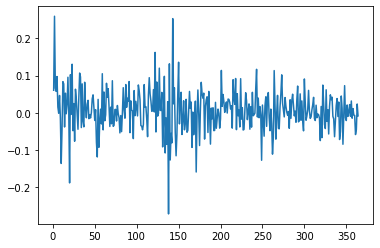

In [18]:
eth_data['Returns'].plot()

In [19]:
eth_data['Returns'].describe()

count    364.000000
mean       0.006027
std        0.056068
min       -0.272003
25%       -0.022501
50%        0.005946
75%        0.036954
max        0.259475
Name: Returns, dtype: float64

# Returns Analysis

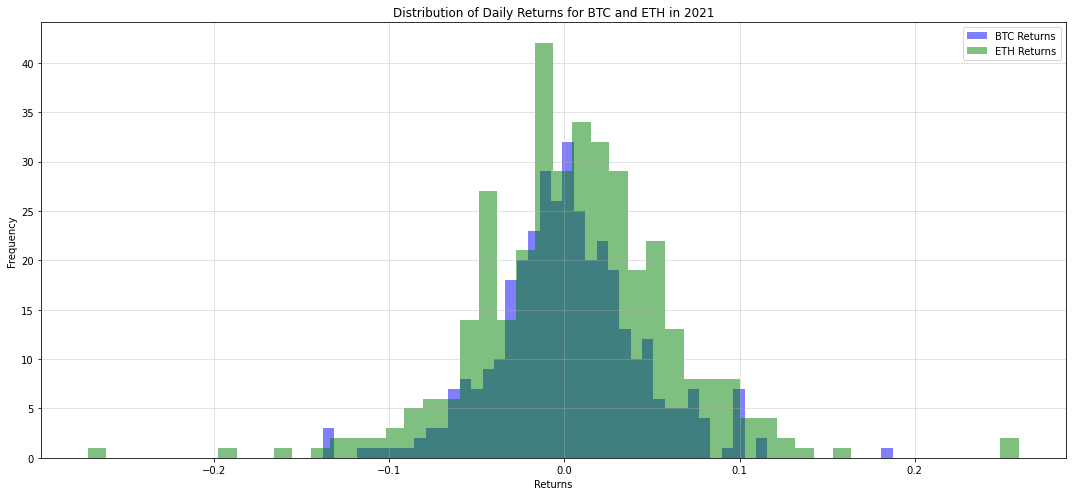

In [20]:
plt.figure(figsize=(15, 7))

# Bitcoin
plt.hist(btc_data['Returns'].dropna(), bins=50, alpha=0.5, label='BTC Returns', color='blue')

# Ethereum
plt.hist(eth_data['Returns'].dropna(), bins=50, alpha=0.5, label='ETH Returns', color='green')

# Formatting the plot
plt.title('Distribution of Daily Returns for BTC and ETH in 2021')
plt.xlabel('Returns')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.tight_layout()

plt.show()

# Volatility

<Axes: >

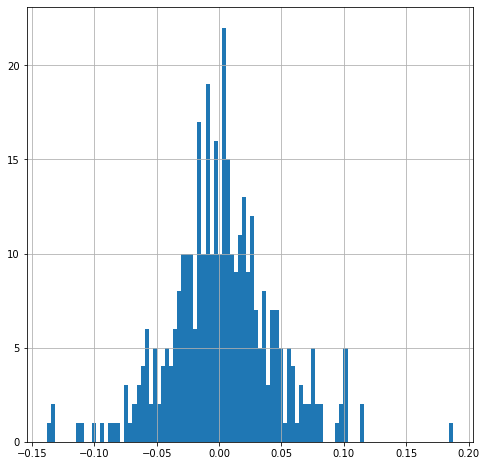

In [21]:
btc_data['Returns'].hist(bins=100, figsize=(8, 8))

<Axes: >

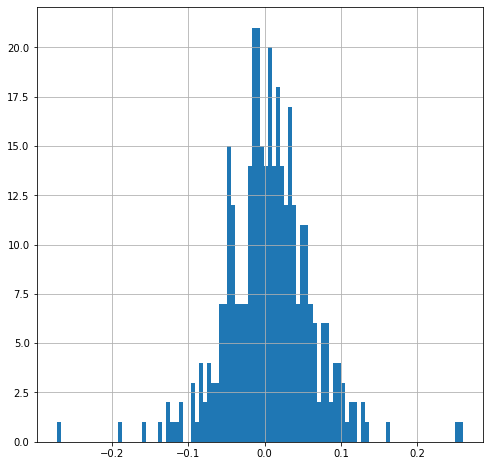

In [22]:
eth_data['Returns'].hist(bins=100, figsize=(8, 8))

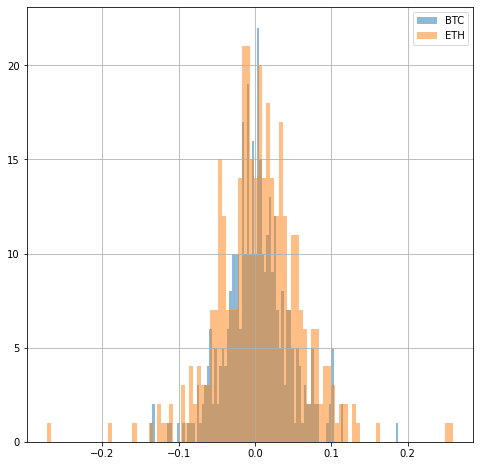

In [23]:
btc_data['Returns'].hist(bins=100, label='BTC', alpha=0.5, figsize=(8, 8))
eth_data['Returns'].hist(bins=100, label='ETH', alpha=0.5)
plt.legend()

# kernel density estimate plot

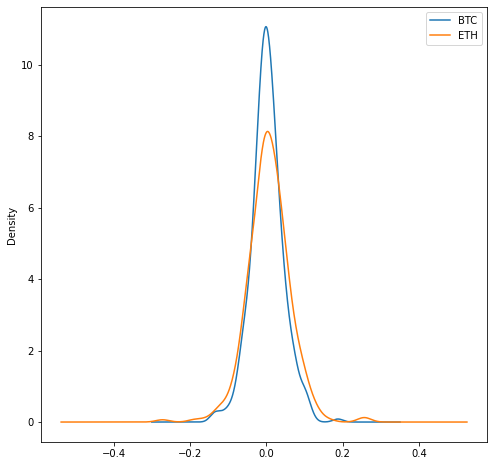

In [24]:
btc_data['Returns'].plot(kind='kde', label='BTC', figsize=(8, 8))
eth_data['Returns'].plot(kind='kde', label='ETH')
plt.legend()

# Box Plot

<Axes: >

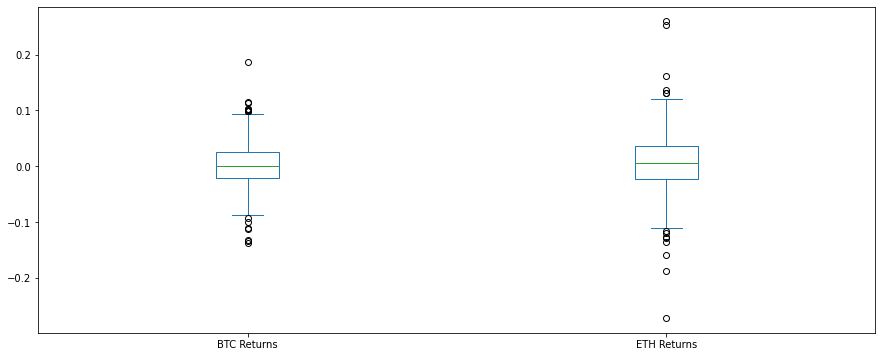

In [25]:
box = pd.concat([btc_data['Returns'], eth_data['Returns']], axis = 1)
box.columns = ['BTC Returns', 'ETH Returns']
box.plot(kind='box', figsize=(15, 6))

# Volume Analysis

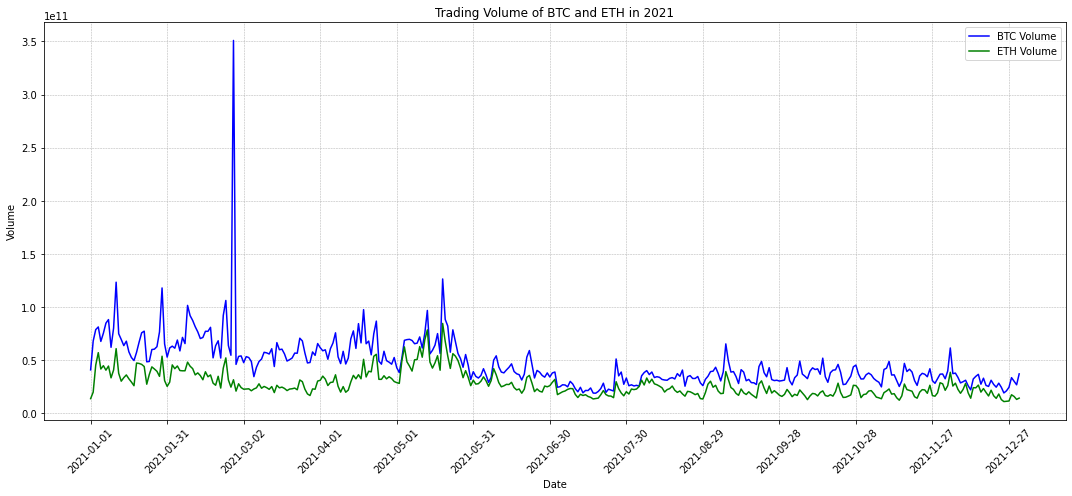

In [26]:
plt.figure(figsize=(15, 7))

plt.plot(btc_data['Date'], btc_data['Volume'], label='BTC Volume', color='blue')
plt.plot(eth_data['Date'], eth_data['Volume'], label='ETH Volume', color='green')

plt.title('Trading Volume of BTC and ETH in 2021')
plt.xlabel('Date')
plt.ylabel('Volume')
plt.xticks(btc_data['Date'][::30], rotation=45)
plt.legend()
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.tight_layout()

plt.show()


# Lag Plot

<Axes: xlabel='y(t)', ylabel='y(t + 1)'>

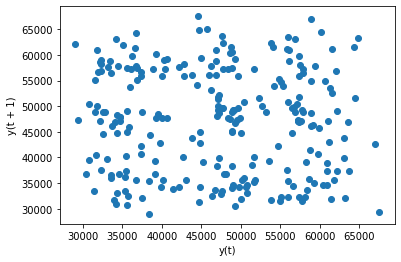

In [27]:
lag_plot(btc_data['Open'].sample(250))

<Axes: xlabel='y(t)', ylabel='y(t + 1)'>

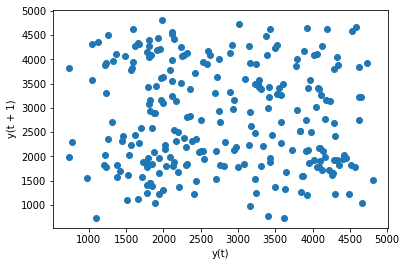

In [28]:
lag_plot(eth_data['Open'].sample(250))

# Autocorrelation Plot

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

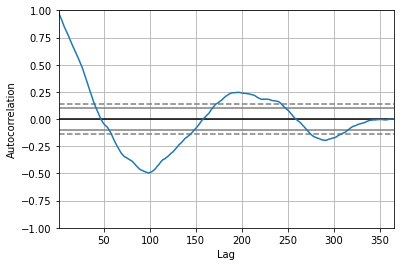

In [29]:
autocorrelation_plot(btc_data['Open'])

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

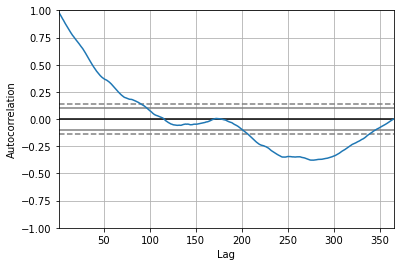

In [30]:
autocorrelation_plot(eth_data['Open'])

# Correlation Analysis

Correlation: 0.7615674802888224


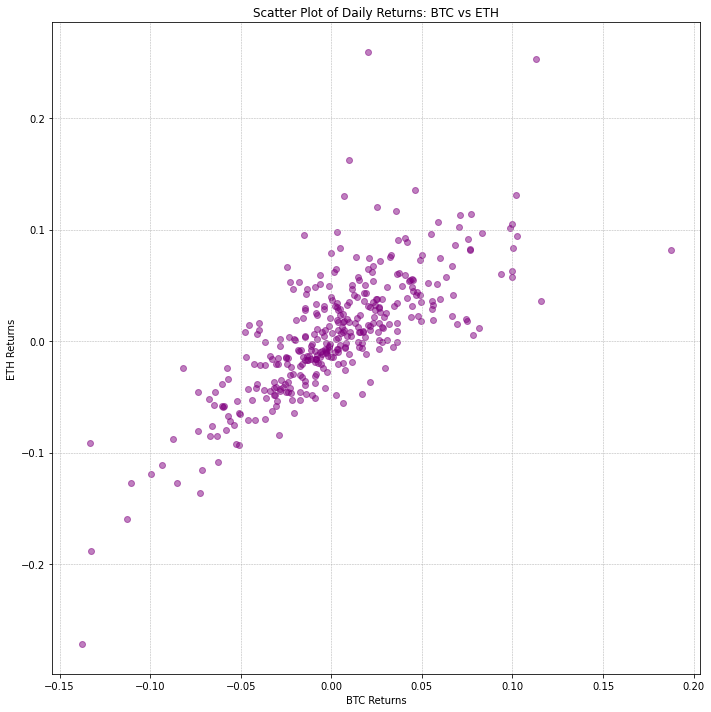

In [31]:
# Compute correlation
correlation = btc_data['Returns'].dropna().corr(eth_data['Returns'].dropna())
print(f"Correlation: {correlation}")

# Scatter plot
plt.figure(figsize=(10, 10))
plt.scatter(btc_data['Returns'].dropna(), eth_data['Returns'].dropna(), alpha=0.5, color='purple')
plt.title('Scatter Plot of Daily Returns: BTC vs ETH')
plt.xlabel('BTC Returns')
plt.ylabel('ETH Returns')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()

# Candlestick Plot

In [32]:
btc_data['Date'] = pd.to_datetime(btc_data['Date'])
BTC_reset = btc_data.set_index('Date').loc['2021-01':'2021-12'].reset_index()

In [33]:
eth_data['Date'] = pd.to_datetime(eth_data['Date'])
ETH_reset = eth_data.set_index('Date').loc['2021-01':'2021-12'].reset_index()

In [34]:
fig = go.Figure(data=[go.Candlestick(x=BTC_reset['Date'],
                open=BTC_reset['Open'],
                high=BTC_reset['High'],
                low=BTC_reset['Low'],
                close=BTC_reset['Close'])])

# Setting the layout and title
fig.update_layout(title='Bitcoin (BTC) Candlestick Chart for 2021',
                 xaxis_title='Date',
                 yaxis_title='Price (USD)',
                 xaxis_rangeslider_visible=False)

fig.show()

In [35]:
fig = go.Figure(data=[go.Candlestick(x=ETH_reset['Date'],
                open=ETH_reset['Open'],
                high=ETH_reset['High'],
                low=ETH_reset['Low'],
                close=ETH_reset['Close'])])

# Setting the layout and title
fig.update_layout(title='Ethereum (ETH) Candlestick Chart for 2021',
                 xaxis_title='Date',
                 yaxis_title='Price (USD)',
                 xaxis_rangeslider_visible=False)

fig.show()

# High-Low Spread Analysis

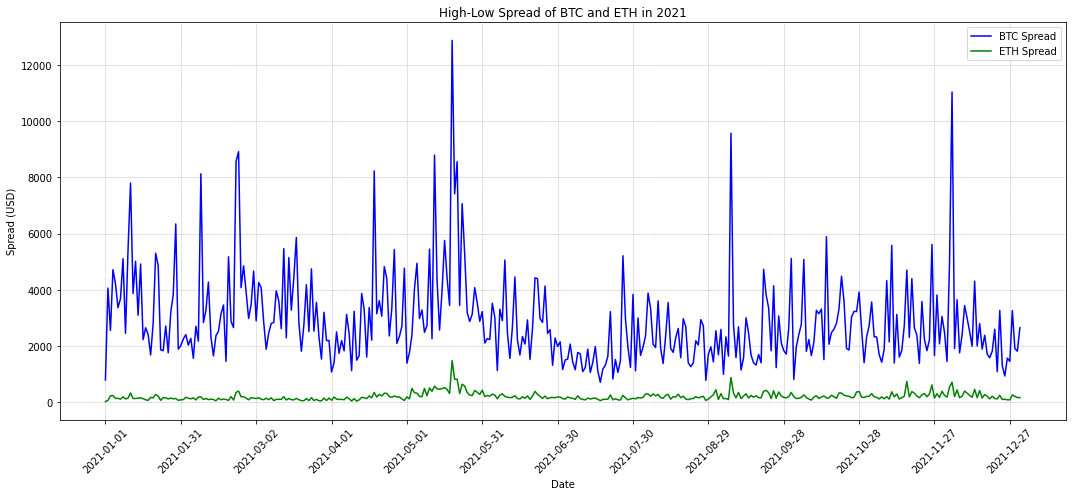

In [36]:
btc_data['Spread'] = btc_data['High'] - btc_data['Low']
eth_data['Spread'] = eth_data['High'] - eth_data['Low']

plt.figure(figsize=(15, 7))

# Bitcoin
plt.plot(btc_data['Date'], btc_data['Spread'], label='BTC Spread', color='blue')

# Ethereum
plt.plot(eth_data['Date'], eth_data['Spread'], label='ETH Spread', color='green')

# Formatting the plot
plt.title('High-Low Spread of BTC and ETH in 2021')
plt.xlabel('Date')
plt.ylabel('Spread (USD)')
plt.xticks(btc_data['Date'][::30], rotation=45)
plt.legend()
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.tight_layout()

plt.show()